# Análisis Exploratorio - Hex AI

Este notebook contiene experimentos interactivos para analizar el comportamiento
de los distintos jugadores de HEX implementados.

In [1]:
import sys
sys.path.append("..")  # para poder importar src desde notebooks/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.hex_ai.board import HexBoard
from src.hex_ai.game import HexGame
from src.hex_ai.players.random_player import RandomPlayer
from src.hex_ai.players.greedy_player import GreedyPlayer
from src.hex_ai.players.minimax_player import MinimaxPlayer
from src.hex_ai.players.mcts_player import MCTSPlayer

sns.set_theme(style="whitegrid")
print("Imports OK")

Imports OK


## 1. Visualización del tablero

Creamos un tablero y colocamos algunas fichas para ver la representación ASCII.

In [2]:
b = HexBoard(7)
b.place(0, 3, 1)
b.place(1, 3, 1)
b.place(2, 3, 1)
b.place(3, 4, 2)
b.place(4, 4, 2)
print(b)
print(f"\n¿Gana jugador 1? {b.is_winner(1)}")
print(f"¿Gana jugador 2? {b.is_winner(2)}")
print(f"Celdas vacías: {len(b.empty_cells())}")

. . . X . . .
 . . . X . . .
  . . . X . . .
   . . . . O . .
    . . . . O . .
     . . . . . . .
      . . . . . . .

¿Gana jugador 1? False
¿Gana jugador 2? False
Celdas vacías: 44


## 2. Una partida de ejemplo

Enfrentamos Greedy vs Random y contamos el número de turnos.

In [3]:
p1 = GreedyPlayer(1)
p2 = RandomPlayer(2)
game = HexGame(p1, p2, size=7, verbose=False)
winner = game.play()
print(f"Ganador: {winner}")
print(f"Turnos: {len(game.history)}")
print(f"Última jugada: {game.history[-1]}")

Ganador: 1
Turnos: 45
Última jugada: (1, (6, 2))


## 3. ¿Cuánto tarda cada jugador por jugada?

Medimos el tiempo medio de `play()` para cada tipo de jugador en un tablero 7x7.

In [4]:
def time_player(player, board, n=10):
    """Mide el tiempo medio de n llamadas a player.play(board)."""
    times = []
    for _ in range(n):
        b = board.clone()
        t0 = time.time()
        player.play(b)
        times.append(time.time() - t0)
    return np.mean(times), np.std(times)

# Tablero inicial con algunas fichas
b0 = HexBoard(7)
b0.place(3, 3, 1)
b0.place(3, 4, 2)

players = {
    "Random": RandomPlayer(1),
    "Greedy": GreedyPlayer(1),
    "Minimax_d2": MinimaxPlayer(1, depth=2, time_limit=2.0),
    "Minimax_d3": MinimaxPlayer(1, depth=3, time_limit=3.0),
    "MCTS_1s": MCTSPlayer(1, time_limit=1.0, iterations=300),
}

results = []
for name, p in players.items():
    mean, std = time_player(p, b0, n=5)
    results.append({"player": name, "mean_time": mean, "std": std})
    print(f"{name:12s}: {mean:.3f} ± {std:.3f} s")

df_times = pd.DataFrame(results)
df_times

Random      : 0.000 ± 0.000 s
Greedy      : 0.000 ± 0.000 s
Minimax_d2  : 0.020 ± 0.002 s
Minimax_d3  : 0.205 ± 0.005 s
MCTS_1s     : 1.003 ± 0.001 s


,player,mean_time,std
0,Random,0.000019,0.000009
1,Greedy,0.000143,0.000006
2,Minimax_d2,0.020295,0.001804
3,Minimax_d3,0.205086,0.005254
4,MCTS_1s,1.002623,0.000682


## 4. Comparación visual de tiempos

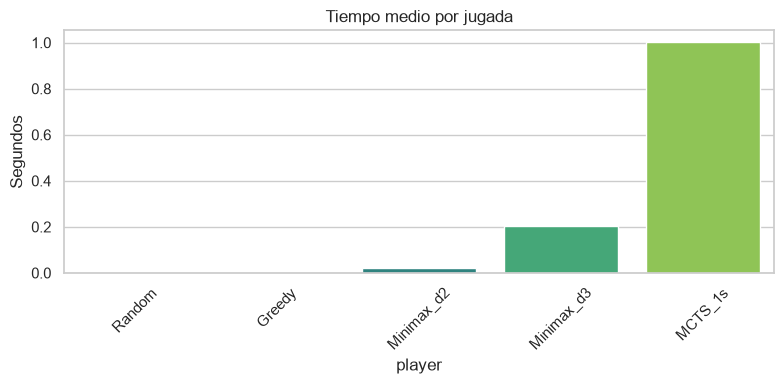

In [5]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_times, x="player", y="mean_time",
            hue="player", palette="viridis", legend=False)
plt.title("Tiempo medio por jugada")
plt.ylabel("Segundos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Win rate de Minimax vs Random según profundidad

Enfrentamos Minimax con distintas profundidades contra Random y medimos el win rate.

In [6]:
def win_rate(player1_class, player2_class, games=10, size=7, **kwargs):
    wins = {1: 0, 2: 0, None: 0}
    for _ in range(games):
        p1 = player1_class(1, **kwargs)
        p2 = player2_class(2)
        game = HexGame(p1, p2, size=size, verbose=False)
        w = game.play()
        wins[w] += 1
    return wins

for depth in [1, 2, 3]:
    w = win_rate(MinimaxPlayer, RandomPlayer, games=10, size=7,
                 depth=depth, time_limit=3.0)
    print(f"Minimax depth={depth} vs Random: {w}")

Minimax depth=1 vs Random: {1: 9, 2: 1, None: 0}
Minimax depth=2 vs Random: {1: 9, 2: 1, None: 0}
Minimax depth=3 vs Random: {1: 8, 2: 2, None: 0}


## 6. Ventaja del primer jugador

Comprobamos cuántas veces gana el jugador que empieza en Random vs Random.

In [8]:
n = 100
first_wins = 0
second_wins = 0
for _ in range(n):
    p1 = RandomPlayer(1)
    p2 = RandomPlayer(2)
    game = HexGame(p1, p2, size=7, verbose=False)
    w = game.play()
    if w == 1:
        first_wins += 1
    elif w == 2:
        second_wins += 1

print(f"En {n} partidas Random vs Random (7x7):")
print(f"  Primer jugador ganó: {first_wins} ({100*first_wins/n:.1f}%)")
print(f"  Segundo jugador ganó: {second_wins} ({100*second_wins/n:.1f}%)")

# Test binomial
from scipy import stats
p = stats.binomtest(first_wins, first_wins + second_wins, 0.5).pvalue
print(f"  Test binomial (H0: 50/50): p={p:.4f}")
if p < 0.05:
    print("  → Ventaja significativa del primer jugador")
else:
    print("  → Sin ventaja significativa")

En 100 partidas Random vs Random (7x7):
  Primer jugador ganó: 60 (60.0%)
  Segundo jugador ganó: 40 (40.0%)
  Test binomial (H0: 50/50): p=0.0569
  → Sin ventaja significativa
